<div style="background:#152238;color:white;border-radius:14px;padding:28px 32px;">
 <div style="color:#9de2dc;letter-spacing:2px;font-size:12px;font-weight:bold;">AI ALGORITHMS · CSP LAB</div>
 <h1 style="text-align:center;color:white;margin:18px 0 12px;">Lab 4 — Constraint Satisfaction Problems</h1>
 <div style="text-align:center;color:#eebe5c;letter-spacing:2px;font-size:14px;font-weight:bold;">Pacman and Sudoku</div>
</div>

## Learning objectives

- Analyze a CSP and justify domain filtering and search choices.
- Implement Pacman's new house from scratch using backtracking, filtering and heuristics.
- Discover OR-Tools through its documentation and a basic worked example.
- Choose a CSP approach for Sudoku, justify the implementation and discuss the results.

## Contents

1. [Part I — Pacman's new house](#part-i)
2. [Part II — From a CSP implementation to OR-Tools](#part-ii)
   - II.1 — Implement Pacman from scratch
   - II.2 — Filtering and heuristics
   - II.3 — Discover OR-Tools: documentation and a provided example
3. [Part III — Sudoku: choose and justify your approach](#part-iii)
4. [Prepare for Oral Assessment 2 — Parts II and III](#oral-assessment)
5. [Oral Assessment 2 — Submission](#submission)

Write your own implementations and explanations. A basic OR-Tools example is provided in II.3; the Sudoku implementation is your work.

<div class="oral2-scope-notice" style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:16px 0;">
<strong style="color:#7051a4;">ORAL ASSESSMENT 2 — PARTS II AND III ONLY</strong>
<p>Prepare your implementations, results and explanations from Parts II and III. Part I is not assessed in this second oral assessment.</p>
<p>Submit the completed notebook on DVL in <strong>oral assessment 2 deposit</strong>, before the start of the Lab 6 session.</p>
</div>

## Reading the task labels

<span style="color:#a85315;font-weight:bold;">IMPLEMENT · I</span> — write or adapt code.

<span style="color:#7051a4;font-weight:bold;">EXPLAIN · Q</span> — justify choices, interpret results and answer in writing.

<span style="color:#087f8c;font-weight:bold;">OBSERVE · O</span> — read, run and understand a provided example.

The words and labels identify the type of work as well as the colors.

## Working environment

Use Python in Jupyter or Google Colab. The implementation from scratch uses the standard library.
OR-Tools is needed for the provided example in II.3 and for the OR-Tools option in Part III.
If it is missing, use the commented installation line at the start of the example.

If the provided OR-Tools example never finishes or crashes the kernel, the cause is your Python
environment, not your code: see the [technical note in II.3](#ortools-troubleshooting).

<a id="part-i"></a>
<h1 align="left"> <font color='blue'><b> Part I - CSP: Pacman's new house </b></font></a></h1>  

**Pacman's New House:** After years of struggling through mazes, Pacman has finally made peace with the ghosts, Blinky, Pinky, Inky, and Clyde, and invited them to live with him and Ms. Pacman. The move has forced Pacman to change the rooming assignments in his house, which has 6 rooms. He has decided to figure out the new assignments with a CSP in which the variables are Pacman (**P**), Ms. Pacman (**M**), Blinky (**B**), Pinky (**K**), Inky (**I**), and Clyde (**C**). The values are which room they will stay in, from $1$ to $6$, and the constraints are:

   1. No two agents can stay in the same room.
   2. $P > 3$
   3. $K<P$
   4. $M$ is either $5$ or $6$
   5. $P > C$
   6. $B$ is even
   7. $I\neq 1$ and $I\neq 6$
   8. $|I - C| = 1$
   9. $|P - B| = 2$

**a) Constraint graph.** Draw the constraint graph for this problem and justify your representation.

- Nodes : P, M, B, K, I and C
- Unary Constraint : P > 3, M = 5 or M = 6 and I != 1 and I != 6
- Binary Constraint : 
  - This is a complete graph, each node is linekd to all the others.
  - (K, P) for K < P, (P, C) for P > C, (I, C) for |I - C| = 1 and (P, B) pour |P - B| = 2. 

**b) Unary constraints.** Determine the domains after enforcing the unary constraints.

| Variable | Domain |
|:--|:--|
| P | 4 &nbsp; 5 &nbsp; 6 |
| B | 2 &nbsp; 4 &nbsp; 6 |
| C | 1 &nbsp; 2 &nbsp; 3 &nbsp; 4 &nbsp; 5 &nbsp; 6 |
| K | 1 &nbsp; 2 &nbsp; 3 &nbsp; 4 &nbsp; 5 &nbsp; 6 |
| I | 2 &nbsp; 3 &nbsp; 4 &nbsp; 5 |
| M | 5 &nbsp; 6 |

**c) Forward checking.** Assume P = 6. What domains remain after enforcing unary constraints and applying forward checking? Justify the removals.

| Variable | Domain |
|:--|:--|
| P | 6 |
| B | 4 |
| C | 1 &nbsp; 2 &nbsp; 3 &nbsp; 4 &nbsp; 5 |
| K | 1 &nbsp; 2 &nbsp; 3 &nbsp; 4 &nbsp; 5 &nbsp; 6 |
| I | 2 &nbsp; 3 &nbsp; 4 &nbsp; 5 |
| M | 5 |

**d) Arc consistency.** Starting from (c), enforce arc consistency. Give the resulting domains and the arc revisions and queue updates that lead to removals.

| Variable | Domain |
|:--|:--|
| P | 6 |
| B | 4 |
| C | 1 &nbsp; 2 &nbsp; 3 |
| K | 1 &nbsp; 2 &nbsp; 3 |
| I | 2 &nbsp; 3 |
| M | 5 |

**e) MRV.** After (d), which variable should MRV select for the next non-forced decision? Justify your answer.

We have here thre variables already assigned. The choice needs to be done between C, K and I. MRV choose the variable with the least amount of values which means that I is chosen.

**f) LCV.** For the variable selected in (e), which value should LCV try first? Justify your answer.

LCV choose the value that least contraints all others variables. We chose I :   
- If I = 2 :   
    - For C : |2-C| = 1 => C = 1 || C = 3
    - For K : K != 2 => K = 1 || K = 3
- If I = 3 :   
    - For C : |3-C| = 1 => K = 2
    - For K : K != 3 => K = 1 || K = 2  

So LCV choose I = 2.

**g) Iterative improvement: min-conflicts.** Start anew from this complete assignment:

$$P=6,\quad B=4,\quad C=3,\quad K=2,\quad I=1,\quad M=5.$$

Give each variable's incident violation count. Which variables may min-conflicts select? For each eligible variable, mark every minimum-conflict replacement different from its current value, keeping the other assignments fixed. Justify your marks.

Use pairwise inequalities for `AllDifferent`, include unary violations, and consider replacement rooms 1–6.

| Variable | Number of violated constraints |
|:--|:--|
| P | 0 |
| B | 0 |
| C | 1 |
| K | 0 |
| I | 2 |
| M | 0 |

| Variable | 1 | 2 | 3 | 4 | 5 | 6 |
|:--|:--:|:--:|:--:|:--:|:--:|:--:|
| P | | | | | | |
| B | | | | | | |
| C | | X | | | | |
| K | | | | | | |
| I | | X | | X | | |
| M | | | | | | |

<a id="part-ii"></a>
# Part II — From a CSP implementation to OR-Tools

Use Pacman's new house from Part I throughout this part. Begin with your own CSP implementation,
then explore how OR-Tools represents and solves the same problem. Solve the complete original
problem; P = 6 was only a temporary assumption for the Part I questions.

## II.1 — Implement Pacman from scratch

<div class="csp-task-panel" data-task-kind="IMPLEMENT" style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I1 · Pacman CSP from scratch</strong>
<p>Write your own CSP solver in Python, using only the standard library. Use it to solve Pacman's new house, including every constraint from Part I. Work in three steps.</p>
<p><strong>1. Describe the problem.</strong> Write the Pacman data in Python: the variables, the domain of each variable and the constraints. For example, you can apply the unary constraints directly to the domains, as in Part I (b), and write one function that tells whether the values of two variables are compatible.</p>
<p><strong>2. Write a <code>CSP</code> class.</strong> It stores a problem (variables, domains, constraints) and solves it by recursive backtracking. Keep the class general, so that you can reuse it for another problem, such as Sudoku in Part III: the Pacman data is passed to it, not written inside it. It must provide at least these methods:</p>
<ul>
<li><code>backtracking_search</code>: starts the search and returns a solution, or <code>None</code> if the problem has no solution.</li>
<li><code>recursive_backtracking</code>: the recursive function. It extends the current assignment one variable at a time, and goes back to try another value when a branch fails.</li>
<li><code>is_complete</code>: tells whether every variable has a value.</li>
<li><code>select_unassigned_variable</code>: chooses the next variable to assign.</li>
<li><code>order_domain_values</code>: returns the values to try for a variable, in the order in which to try them.</li>
<li><code>is_consistent</code>: tells whether a value can be given to a variable without violating a constraint with the variables already assigned.</li>
</ul>
<p>In this first version, <code>select_unassigned_variable</code> and <code>order_domain_values</code> can simply follow a fixed order. In II.2, you will add MRV and LCV to them.</p>
<p><strong>3. Solve the problem.</strong> Create the Pacman CSP with your class, run the search and display the assignment it returns.</p>
<p>The parameters of the methods, the data structures and any additional helper methods are your choice.</p>

</div>

<div class="csp-task-panel" data-task-kind="EXPLAIN" style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q1 · Explain your implementation and validate its result</strong>
<p>Present your representation, implementation and a returned assignment. Explain how your solver recognizes a solution and handles an unsuccessful branch, and verify that the result satisfies the problem.</p>

</div>

In [2]:
variables = ["P", "B", "C", "K", "I", "M"]

# Defined in question b
domains = {
    "P": [4, 5, 6],
    "B": [2, 4, 6],
    "C": [1, 2, 3, 4, 5, 6],
    "K": [1, 2, 3, 4, 5, 6],
    "I": [2, 3, 4, 5],
    "M": [5, 6],
}

neighbors = {v: [u for u in variables if u != v] for v in variables}

def pacman_constraint(v1, x, v2, y):
    if x == y:   #Condition All different
        return False
    d = {v1: x, v2: y}
    pair = {v1, v2} # Creating a pair is useful because the order in the list is not important v1,v2 = v2,v1
    if pair == {"K", "P"}:
        return d["K"] < d["P"]
    if pair == {"P", "C"}:
        return d["P"] > d["C"]
    if pair == {"I", "C"}:
        return abs(d["I"] - d["C"]) == 1
    if pair == {"P", "B"}:
        return abs(d["P"] - d["B"]) == 2
    return True

class CSP:
    def __init__(self, variables, domains, neighbors, constraint):
        self.variables = variables
        self.domains = domains
        self.neighbors = neighbors
        self.constraint = constraint

    def is_complete(self, assignment):
        return len(assignment) == len(self.variables)

    def select_unassigned_variable(self, assignment):
        for v in self.variables:
            if v not in assignment:
                return v

    def order_domain_values(self, var, assignment):
        return self.domains[var]

    def is_consistent(self, var, val, assignment):
        for other_var, other_val in assignment.items():
            if other_var in self.neighbors[var]:
                if not self.constraint(var, val, other_var, other_val):
                    return False
        return True

    def backtracking_search(self):
        return self.recursive_backtracking({})

    def recursive_backtracking(self, assignment):
        if self.is_complete(assignment):
            return assignment

        var = self.select_unassigned_variable(assignment)
        for val in self.order_domain_values(var, assignment):
            if self.is_consistent(var, val, assignment):
                assignment[var] = val
                result = self.recursive_backtracking(assignment)
                if result is not None:
                    return result
                del assignment[var]
        return None


csp_base = CSP(variables, domains, neighbors, pacman_constraint)
solution_ii1 = csp_base.backtracking_search()
print("Solution :", solution_ii1)

Solution : {'P': 4, 'B': 6, 'C': 1, 'K': 3, 'I': 2, 'M': 5}


**Your work and discussion:**

1. Problem Representation
    - Variables: P, B, C, K, I and M. We reprentent it in a list.
    - Domains: We defined a dictionnary with each node as index (from 1 to 6). And to each node we assigned the constraints defined in question b(P > 3, B even, I != 1 and 6, and M in {5, 6}). This dictionnary is used directly in the code later.   
    - Constraints: A neighbors dictionary connects every character to all others. Also there is a function pacman_constraint which checks if any two assigned rooms obey all binary rules : true if it's good false .    
2. Solver
    - The is_complete method checks if all 6 variables are present in the assignment dictionary. Values are added after thanks to the is_consistent method, which means reaching 6 assigned variables guarantees a valid solution.   
    - In the recursive_backtracking method, the solver picks the next unassigned variable and tries its values one by one. If a value violates a constraint or leads to a impossible graph (returning None), the solver undoes that choice (delete the var) and backtracks to try the next value.   
3. Results    
The solver returns: ('P': 4, 'B': 6, 'C': 1, 'K': 3, 'I': 2, 'M': 5)
    - Rooms {4, 6, 1, 3, 2, 5} are all different.   
    - P = 4 > 3.   
    - K = 3 < P = 4.   
    - M = 5 is in {5, 6}.   
    - P = 4 > C = 1.   
    - B = 6 is even.   
    - I = 2 is different from 1 and 6.   
    - |I - C| = |2 - 1| = 1.   
    - |P - B| = |4 - 6| = 2.   
    
The result is valid.

## II.2 — Filtering and heuristics

<div class="csp-task-panel" data-task-kind="IMPLEMENT" style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I2 · Extend your solver</strong>
<p>Extend your solver to obtain these versions:</p>
<ul>
<li>Backtracking with forward checking.</li>
<li>Backtracking with forward checking and AC-3.</li>
<li>Backtracking with forward checking, MRV and LCV.</li>
<li>Backtracking with forward checking, AC-3, MRV and LCV.</li>
</ul>
<p>In Q2, you will compare these four versions with each other and with plain backtracking from II.1. Your code must also measure the indicators you choose for this comparison, for example those listed in Q2.</p>

</div>

<div class="csp-task-panel" data-task-kind="EXPLAIN" style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q2 · Choose indicators, compare and discuss</strong>
<p>Compare the four versions above with each other and with plain backtracking from II.1, used as the baseline. Run all five on the same Pacman problem. Choose and justify relevant indicators for your comparison.</p>
<p><strong>The criteria below are illustrative and non-exhaustive, not a compulsory checklist. Other relevant indicators that you identify are welcome.</strong> Explain what your chosen indicators reveal about the search.</p>
<table style="border-collapse:collapse;width:100%;color:#182b45;">
<thead>
<tr>
<th style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Example criterion</th>
<th style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Possible measurement</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Solving time</td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Elapsed time until the first solution is found, excluding printing and plotting.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Node expansions</td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Consistent candidate assignments accepted during search, including those whose subsequent filtering fails.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Backtracks</td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Accepted assignments undone after an unsuccessful branch.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Constraint checks</td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Unary or binary constraint tests, including checks performed by filtering and heuristic calculations.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Pruned values</td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Values actually removed from working domains by filtering during search.</td>
</tr>
<tr>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Attempted assignments</td>
<td style="padding:7px 9px;border-bottom:1px solid #d4dbe3;text-align:left;">Candidate values tried, including those rejected by consistency checks.</td>
</tr>
</tbody>
</table>
<p>For whichever indicators you select, define them clearly and apply the same conventions to every version. If you count constraint checks, state what constitutes one test. If you count pruning, distinguish actual filtering deletions from rejected candidates and decision-domain restrictions, and state how you handle initial filtering and repeated deletions in different branches.</p>
<p>Make the comparison fair: use fresh domains, the same input and stopping condition, and consistent tie-breaking rules. If you measure time, repeat runs to reduce noise. Attribute an effect to one technique only when the compared versions differ in that technique.</p>
<p>Present your results in a suitable form and interpret the impact of the additions using your chosen indicators. Discuss trade-offs, such as search saved versus extra filtering or heuristic work. Explain any differences between returned assignments and justify their validity.</p>

</div>

In [ ]:
import time


class ExtendedCSP(CSP):
    def __init__(self, variables, domains, neighbors, constraint):
        super().__init__(variables, domains, neighbors, constraint)
        self.expansions = 0
        self.backtracks = 0
        self.checks = 0
        self.pruned = 0

    def is_consistent(self, var, val, assignment):
        for other_var, other_val in assignment.items():
            if other_var in self.neighbors[var]:
                self.checks += 1
                if not self.constraint(var, val, other_var, other_val):
                    return False
        return True

    def select_unassigned_variable(self, assignment, domains, use_mrv=False):
        unassigned = []
        for v in self.variables:
            if v not in assignment:
                unassigned.append(v)

        if not use_mrv:
            return unassigned[0]

        # MRV : We choose the variable with the smallest domain
        best_var = unassigned[0]
        for v in unassigned:
            if len(domains[v]) < len(domains[best_var]):
                best_var = v
        return best_var

    def order_domain_values(self, var, assignment, domains, use_lcv=False):
        if not use_lcv:
            return domains[var]

        # LCV : We count the number of eliminated values for the neighbour
        def count_eliminated_values(val):
            eliminated = 0
            for neighbor in self.neighbors[var]:
                if neighbor not in assignment:
                    for neighbor_val in domains[neighbor]:
                        self.checks += 1
                        if not self.constraint(var, val, neighbor, neighbor_val):
                            eliminated += 1
            return eliminated

        return sorted(domains[var], key=count_eliminated_values)

    def forward_checking(self, var, val, assignment, domains):
        # Copy of the actual domain to keep those from the previous branchs
        new_domains = {}
        for v in self.variables:
            new_domains[v] = list(domains[v])
        new_domains[var] = [val]

        # We verufy each neighbour non assigned
        for neighbor in self.neighbors[var]:
            if neighbor not in assignment:
                valid_values = []
                for neighbor_val in new_domains[neighbor]:
                    self.checks += 1
                    if self.constraint(var, val, neighbor, neighbor_val):
                        valid_values.append(neighbor_val)
                    else:
                        self.pruned += 1

                # Return None if a neighbour has no possible value left
                if len(valid_values) == 0:
                    return None
                new_domains[neighbor] = valid_values

        return new_domains

    def ac3(self, domains):
        queue = []
        for xi in self.variables:
            for xj in self.neighbors[xi]:
                queue.append((xi, xj))

        while len(queue) > 0:
            xi, xj = queue.pop(0)
            revised = False

            for x in list(domains[xi]):
                has_valid_y = False
                for y in domains[xj]:
                    self.checks += 1
                    if self.constraint(xi, x, xj, y):
                        has_valid_y = True
                        break

                if not has_valid_y:
                    domains[xi].remove(x)
                    self.pruned += 1
                    revised = True

            if revised:
                if len(domains[xi]) == 0:
                    return False
                for xk in self.neighbors[xi]:
                    if xk != xj:
                        queue.append((xk, xi))

        return True

    def backtracking_search(self, use_fc=False, use_ac3=False, use_mrv=False, use_lcv=False):
        self.expansions = 0
        self.backtracks = 0
        self.checks = 0
        self.pruned = 0

        # Fresh copy of the inital domains
        work_domains = {}
        for v in self.variables:
            work_domains[v] = list(self.domains[v])

        if use_ac3:
            if not self.ac3(work_domains):
                return None

        return self.recursive_backtracking({}, work_domains, use_fc, use_ac3, use_mrv, use_lcv)

    def recursive_backtracking(self, assignment, domains, use_fc, use_ac3, use_mrv, use_lcv):
        if self.is_complete(assignment):
            return assignment

        var = self.select_unassigned_variable(assignment, domains, use_mrv)
        ordered_values = self.order_domain_values(var, assignment, domains, use_lcv)

        for val in ordered_values:
            if self.is_consistent(var, val, assignment):
                self.expansions += 1
                assignment[var] = val

                branch_ok = True
                if use_fc:
                    next_domains = self.forward_checking(var, val, assignment, domains)
                    if next_domains is None:
                        branch_ok = False
                else:
                    next_domains = {}
                    for v in self.variables:
                        next_domains[v] = list(domains[v])
                    next_domains[var] = [val]

                if branch_ok and use_ac3:
                    if not self.ac3(next_domains):
                        branch_ok = False

                if branch_ok:
                    result = self.recursive_backtracking(assignment, next_domains, use_fc, use_ac3, use_mrv, use_lcv)
                    if result is not None:
                        return result

                # Bcktrack if failed
                del assignment[var]
                self.backtracks += 1

        return None


csp_ext = ExtendedCSP(variables, domains, neighbors, pacman_constraint)

versions = [
    ("1. Plain Backtracking",      dict(use_fc=False, use_ac3=False, use_mrv=False, use_lcv=False)),
    ("2. BT + FC",                 dict(use_fc=True,  use_ac3=False, use_mrv=False, use_lcv=False)),
    ("3. BT + FC + AC-3",          dict(use_fc=True,  use_ac3=True,  use_mrv=False, use_lcv=False)),
    ("4. BT + FC + MRV + LCV",     dict(use_fc=True,  use_ac3=False, use_mrv=True,  use_lcv=True)),
    ("5. BT + FC + AC-3 + MRV+LCV",dict(use_fc=True,  use_ac3=True,  use_mrv=True,  use_lcv=True)),
]

for name, params in versions:
    t0 = time.perf_counter()
    sol = csp_ext.backtracking_search(**params)
    dt = (time.perf_counter() - t0) * 1000
    print(f"{name:<27} | Exp: {csp_ext.expansions:<2} | BT: {csp_ext.backtracks:<2} | Checks: {csp_ext.checks:<4} | Pruned: {csp_ext.pruned:<2} | {dt:.3f} ms | {sol}")

1. Plain Backtracking       | Exp: 12 | BT: 6  | Checks: 83   | Pruned: 0  | 0.161 ms | {'P': 4, 'B': 6, 'C': 1, 'K': 3, 'I': 2, 'M': 5}
2. BT + FC                  | Exp: 10 | BT: 4  | Checks: 85   | Pruned: 22 | 0.121 ms | {'P': 4, 'B': 6, 'C': 1, 'K': 3, 'I': 2, 'M': 5}
3. BT + FC + AC-3           | Exp: 7  | BT: 1  | Checks: 556  | Pruned: 19 | 0.699 ms | {'P': 4, 'B': 6, 'C': 1, 'K': 3, 'I': 2, 'M': 5}
4. BT + FC + MRV + LCV      | Exp: 6  | BT: 0  | Checks: 175  | Pruned: 14 | 0.183 ms | {'M': 5, 'P': 6, 'B': 4, 'I': 2, 'C': 1, 'K': 3}
5. BT + FC + AC-3 + MRV+LCV | Exp: 6  | BT: 0  | Checks: 682  | Pruned: 15 | 0.777 ms | {'P': 6, 'B': 4, 'M': 5, 'I': 2, 'C': 1, 'K': 3}


**Your work and discussion:**

1. Chosen Indicators and Conventions   
To make a good comparison, all 5 versions run on the exact same Pacman problem, with domain copies and the same stopping condition (the first valid solution). We chose 5 indicators:   
  - Node expansions (Exp): Number of consistent assignments accepted during search.
  - Backtracks (BT): Number of accepted assignments undone when a branch fails.
  - Constraint checks (Checks): Every call to the constraint function.
  - Pruned values (Pruned): Number of values deleted from working domains by Forward Checking or AC-3 during search.
  - Solving time (ms): Elapsed time until the first solution is found.

2. Analysis and Trade-offs
  - Forward Checking (2 vs 1): FC reduces node expansions (12 to 10) and backtracks (6 to 4) by deleting 22 incompatible values from neighbor domains early. The number of checks stays almost the same (83 vs. 85).
  - AC-3 (3 vs 2): AC-3 cuts expansions down to 7 and backtracks to 1 because it propagates constraints across all neighbors. However, it requires 556 (vs 85) constraint checks and takes more time (1.495 ms) because it repeatedly checks arcs.
  - MRV + LCV (4 vs 2): MRV picks the most constrained variables first, and LCV picks the least restricting values first. This gives the best result: 0 backtracks and only 6 expansions (one per variable), with just 175 checks and 0.206 ms.
  - Trade-offs: On a small 6-variable problem, Plain BT is faster in (0.130 ms) because extra filtering and heuristics have a small cost. But for the improved versions, BT + FC + MRV + LCV is the best balance between the time and the number of expansion.
  - Different Solutions: Versions 1–3 return the same list, while versions 4–5 return two different lists. This happens because MRV changes the order in which variables are assigned (M is picked before P). But both solutions satisfy every rule of the problem, so both are valid.

## II.3 — Discover OR-Tools

<div class="csp-task-panel" data-task-kind="OBSERVE" style="border-left:5px solid #087f8c;background:#eef9f8;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#087f8c;">OBSERVE · O1 · Read the documentation and run the provided example</strong>
<p>In practical CSP applications, we usually rely on an existing solver library rather than
reimplement backtracking, filtering and heuristics for every problem. Building a solver from
scratch in this lab helps us understand the mechanisms that established solvers provide.</p>
<p>Our main task is to <strong>formalize the problem</strong>: define its variables, their domains and the
constraints they must satisfy, then pass this model to a solver. The solver uses the constraints
to reduce the remaining possibilities and searches for a compatible assignment. It returns a
solution or a status describing the outcome. The exact search and propagation methods depend
on the solving engine.</p>
<p>OR-Tools is one such toolkit for constraint and optimization problems. The example below uses
its CP-SAT solver to model integer variables and constraints, then find a feasible assignment.
Our work focuses on describing the problem; the library manages the solving process.</p>
<p>Other options are available in Python and other languages, for example
<a href="https://github.com/python-constraint/python-constraint">python-constraint2</a> for Python,
<a href="https://choco-solver.org/">Choco</a> for Java, and
<a href="https://www.minizinc.org/">MiniZinc</a>, a constraint modeling language with several solver backends
and a Python interface. These tools can also be used to model and solve CSPs.</p>
<p>Start with the official <a href="https://developers.google.com/optimization/cp/cp_solver">CP-SAT guide and its Python examples</a>.
The <a href="https://developers.google.com/optimization/introduction/python">general OR-Tools introduction for Python</a>
provides additional context and examples.</p>
<p>A basic implementation of Pacman's problem is supplied below. Read it alongside the documentation
and run it after completing your implementation from scratch.</p>

</div>

<a id="ortools-troubleshooting"></a>
<div class="csp-technical-note" style="border-left:5px solid #5f6b7a;background:#f3f5f8;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#5f6b7a;">TECHNICAL NOTE · Running the OR-Tools example</strong>
<p><strong>What is normal.</strong> The example below is small. It should finish within a few seconds
the first time, because OR-Tools must be imported, and almost instantly when you run it again.
The assignment it prints may change from one run to the next and may differ from the one saved
in this notebook: the solver searches with several workers in parallel, and this problem has
several solutions. Any assignment that satisfies all the constraints is correct.</p>
<p><strong>What is not normal.</strong> The cell never finishes, or the kernel stops. VS Code then shows
<em>“The Kernel crashed while executing code in the current cell or a previous cell”</em>, sometimes
under an earlier cell. Jupyter says that the kernel <em>“appears to have died”</em>. For this provided
example, the cause is your Python environment, <strong>not the model and not your code</strong>.</p>
<p>A typical cause is an Anaconda environment in which <code>ortools</code> was installed with <code>pip</code>
next to the <code>pyarrow</code> package installed by conda. The two bring incompatible copies of the
same library (protobuf), and Python stops at the line
<code>from ortools.sat.python import cp_model</code>.</p>
<p><strong>What to do.</strong> Run the notebook in an environment without this conflict:</p>
<ul>
<li><strong>Google Colab:</strong> uncomment the line <code>%pip install ortools</code> at the top of the example
to install OR-Tools, and restart the session if Colab asks you to.</li>
<li><strong>On your computer:</strong> create a separate environment for this lab. In a terminal
(Anaconda Prompt on Windows):
<pre style="background:#e6eaf0;color:#182b45;padding:9px 12px;border-radius:4px;">conda create -n csp-lab python=3.11 ipykernel
conda activate csp-lab
pip install ortools
python -m ipykernel install --user --name csp-lab --display-name "Python (csp-lab)"</pre>
Then select the kernel <strong>Python (csp-lab)</strong> for this notebook and run the notebook again
from the top. In VS Code, click the kernel name at the top right of the notebook, then
<em>Select Another Kernel</em>. In Jupyter, use the menu <em>Kernel → Change Kernel</em>.</li>
</ul>
<p>The same crash can affect any cell that imports OR-Tools, including the OR-Tools option in
Part III. Your implementation from scratch uses only the standard library and is not affected.</p>

</div>

In [4]:
# If OR-Tools is missing in this notebook environment:
#%pip install ortools

from ortools.sat.python import cp_model

# 1. Create the model.
model = cp_model.CpModel()

# 2. Create the room variables. Unary restrictions are in their domains.
P = model.new_int_var(4, 6, "P")                 # P > 3
B = model.new_int_var_from_domain(
    cp_model.Domain.from_values([2, 4, 6]), "B") # B is even
C = model.new_int_var(1, 6, "C")
K = model.new_int_var(1, 6, "K")
I = model.new_int_var(2, 5, "I")                 # I != 1 and I != 6
M = model.new_int_var(5, 6, "M")                 # M is 5 or 6

# 3. Add the constraints involving several variables.
model.add_all_different([P, B, C, K, I, M])        # One room per character
model.add(K < P)
model.add(P > C)
model.add_abs_equality(1, I - C)                  # |I - C| = 1
model.add_abs_equality(2, P - B)                  # |P - B| = 2

# 4. Solve the model with the basic solver settings.
solver = cp_model.CpSolver()
status = solver.solve(model)

# 5. Read values only if the solver found a solution.
ortools_solution = None
print("Status:", solver.status_name(status))
if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    ortools_solution = {
        "P": solver.value(P), "B": solver.value(B),
        "C": solver.value(C), "K": solver.value(K),
        "I": solver.value(I), "M": solver.value(M),
    }
    print("Solution:", ortools_solution)
else:
    print("No solution was returned.")

Status: OPTIMAL
Solution: {'P': 6, 'B': 4, 'C': 2, 'K': 1, 'I': 3, 'M': 5}




<div class="csp-task-panel" data-task-kind="EXPLAIN" style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q3 · Interpret the provided OR-Tools example</strong>
<p>Explain the role of the model and the solver, identify how the constraints are represented in the provided example, and compare the returned assignment and modeling approach with your own CSP implementation.</p>

</div>

**Your work and discussion:**

1. Role of the Model and the Solver
  - The Model : It's used to describe the problem (variable, domain and constraints)
  - The Solver : It's the engine that is used for the resolution. The optimal status means that the solution respects all the contraints.

2. How Constraints are Represented
  - Unary constraints are set directly when creating the variables.
  - The global uniqueness rule uses the native function : model.add_all_different(...).
  - Binary inequalities and distances use direct expressions like model.add(K < P) and model.add_abs_equality(1, I - C).

3. Comparison with Our Implementation
  - Modeling approach: In our code from scratch, we had to write the backtracking search, domain copying, and filtering algorithms ourselves, and check constraints pair by pair. With OR-Tools, we only declare the rules and we can use the native function of the library to solve the problem.
  - Returned assignment: OR-Tools returns {'P': 6, 'B': 4, 'C': 2, 'K': 1, 'I': 3, 'M': 5}, which is different from our solver's solution {'P': 4, 'B': 6, 'C': 1, 'K': 3, 'I': 2, 'M': 5}. This is normal because the problem has several valid solutions.
  - Validation: All rooms {6, 4, 2, 1, 3, 5} are different, P=6 > 3, K=1 < 6, M=5 \in {5,6}, P=6 > C=2, B=4 is even, I=3 not in {1,6}, |3 - 2| = 1, and |6 - 4| = 2. All constraints are respected.

<a id="part-iii"></a>
# Part III — Sudoku: choose and justify your approach

Solve the Sudoku problem from Lab 3 again: the same four puzzles as in Section 7 of `Lab3_Local_Search_GA.ipynb`.
This time, solve it as a CSP instead of using local search or a genetic algorithm.
Choose either **OR-Tools CP-SAT** or **your CSP implementation from scratch** from Part II.

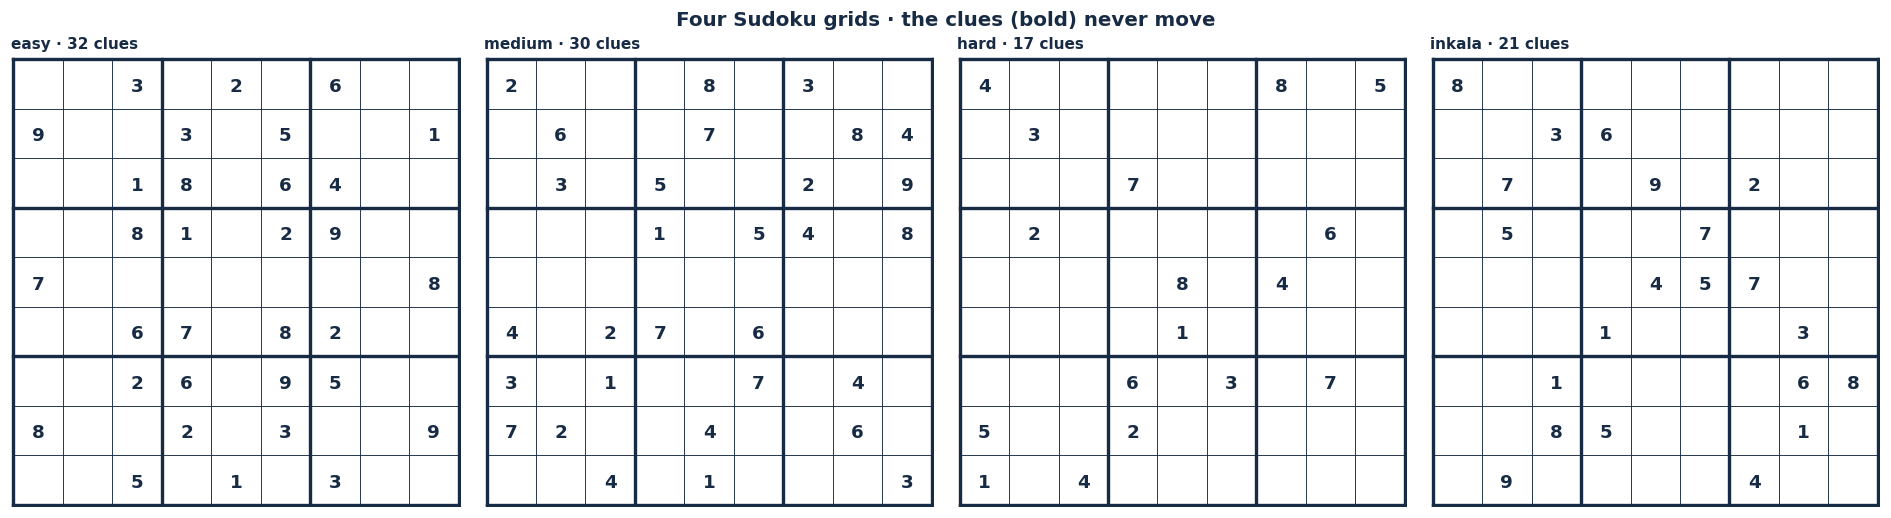

Fill a 9 × 9 grid so that every row, column and 3 × 3 box contains the digits 1–9 exactly once. The given digits, called clues, must remain unchanged.

The grids below are copied from the Lab 3 exercise. Read each sequence row by row; **0 denotes an empty cell**, not an allowed solution digit.

| Grid | Clues | The 81 cells |
|:--|--:|:--|
| easy | 32 | 003020600900305001001806400008102900700000008006708200002609500800203009005010300 |
| medium | 30 | 200080300060070084030500209000105408000000000402706000301007040720040060004010003 |
| hard | 17 | 400000805030000000000700000020000060000080400000010000000603070500200000104000000 |
| inkala | 21 | 800000000003600000070090200050007000000045700000100030001000068008500010090000400 |

## Your task

<div class="csp-task-panel" data-task-kind="IMPLEMENT" style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I3 · Solve Sudoku with your chosen approach</strong>
<p>Choose either OR-Tools CP-SAT or your CSP implementation from scratch. Implement a Sudoku solver using that approach and test it on the supplied grids.</p>
<p>A well-justified, correct implementation using either approach is acceptable.</p>

</div>

<div class="csp-task-panel" data-task-kind="EXPLAIN" style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q4 · Justify your approach, discuss the results and compare with Lab 3</strong>
<ol>
<li>Justify your choice and explain your formulation, implementation and solving procedure. If you reuse the CSP from scratch, explain the adaptations you make for Sudoku.</li>
<li>Present the results, identify the grids solved and any difficulties encountered, and explain how you checked the returned grids.</li>
<li>Discuss what you observe: differences between puzzles, the behavior of your approach and its limitations.</li>
<li>Compare the two solving processes for Sudoku: the CSP approach of this lab and the local-search approach of Lab 3. Describe what you observe: how each one searches for a solution, and what results it gives on the same puzzles. Then say what you conclude about the strengths and limits of each approach. Support your answer with your results from both labs.</li>
</ol>

</div>

In [5]:
# The four original Lab 3 puzzles, read row by row (0 = empty).
sudoku_puzzles = {
    "easy": "003020600900305001001806400008102900700000008006708200002609500800203009005010300",
    "medium": "200080300060070084030500209000105408000000000402706000301007040720040060004010003",
    "hard": "400000805030000000000700000020000060000080400000010000000603070500200000104000000",
    "inkala": "800000000003600000070090200050007000000045700000100030001000068008500010090000400",
}

In [6]:
import time
from ortools.sat.python import cp_model


def solve_sudoku(puzzle_str):
    start_time = time.perf_counter()
    model = cp_model.CpModel()

    # 1. Création des 81 variables (fixées si indice donné, sinon domaine 1..9)
    grid = {}
    for r in range(9):
        for c in range(9):
            val = int(puzzle_str[r * 9 + c])
            if val != 0:
                grid[(r, c)] = model.new_int_var(val, val, f"cell_{r}_{c}")
            else:
                grid[(r, c)] = model.new_int_var(1, 9, f"cell_{r}_{c}")

    # 2. Contraintes AllDifferent sur chaque ligne et chaque colonne
    for i in range(9):
        model.add_all_different([grid[(i, c)] for c in range(9)])
        model.add_all_different([grid[(r, i)] for r in range(9)])

    # 3. Contraintes AllDifferent sur chaque bloc 3x3
    for br in range(3):
        for bc in range(3):
            box = []
            for dr in range(3):
                for dc in range(3):
                    box.append(grid[(br * 3 + dr, bc * 3 + dc)])
            model.add_all_different(box)

    # 4. Résolution
    solver = cp_model.CpSolver()
    status = solver.solve(model)
    elapsed_ms = (time.perf_counter() - start_time) * 1000

    if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        solution = []
        for r in range(9):
            row = [solver.value(grid[(r, c)]) for c in range(9)]
            solution.append(row)
        return solution, elapsed_ms, solver.num_branches, solver.num_conflicts

    return None, elapsed_ms, 0, 0


def is_valid_sudoku(puzzle_str, grid):
    if grid is None:
        return False
    expected = {1, 2, 3, 4, 5, 6, 7, 8, 9}

    # Vérifie que les indices de départ n'ont pas changé
    for r in range(9):
        for c in range(9):
            clue = int(puzzle_str[r * 9 + c])
            if clue != 0 and grid[r][c] != clue:
                return False

    # Vérifie lignes et colonnes
    for i in range(9):
        if set(grid[i]) != expected:
            return False
        if {grid[r][i] for r in range(9)} != expected:
            return False

    # Vérifie les 9 blocs 3x3
    for br in range(3):
        for bc in range(3):
            box = {grid[br * 3 + dr][bc * 3 + dc] for dr in range(3) for dc in range(3)}
            if box != expected:
                return False

    return True


def print_grid(grid):
    for r in range(9):
        if r % 3 == 0 and r != 0:
            print("-" * 21)
        line = ""
        for c in range(9):
            if c % 3 == 0 and c != 0:
                line += "| "
            line += str(grid[r][c]) + " "
        print(line)


# --- Test sur les 4 grilles du TP3 ---
for name, puzzle in sudoku_puzzles.items():
    sol, t_ms, branches, conflicts = solve_sudoku(puzzle)
    valid = is_valid_sudoku(puzzle, sol)
    print(f"=== {name.upper()} | Valid: {valid} | Time: {t_ms:.2f} ms | Branches: {branches} | Conflicts: {conflicts} ===")
    if sol:
        print_grid(sol)
        print()

=== EASY | Valid: True | Time: 18.77 ms | Branches: 0 | Conflicts: 0 ===
4 8 3 | 9 2 1 | 6 5 7 
9 6 7 | 3 4 5 | 8 2 1 
2 5 1 | 8 7 6 | 4 9 3 
---------------------
5 4 8 | 1 3 2 | 9 7 6 
7 2 9 | 5 6 4 | 1 3 8 
1 3 6 | 7 9 8 | 2 4 5 
---------------------
3 7 2 | 6 8 9 | 5 1 4 
8 1 4 | 2 5 3 | 7 6 9 
6 9 5 | 4 1 7 | 3 8 2 

=== MEDIUM | Valid: True | Time: 13.49 ms | Branches: 0 | Conflicts: 0 ===
2 4 5 | 9 8 1 | 3 7 6 
1 6 9 | 2 7 3 | 5 8 4 
8 3 7 | 5 6 4 | 2 1 9 
---------------------
9 7 6 | 1 2 5 | 4 3 8 
5 1 3 | 4 9 8 | 6 2 7 
4 8 2 | 7 3 6 | 9 5 1 
---------------------
3 9 1 | 6 5 7 | 8 4 2 
7 2 8 | 3 4 9 | 1 6 5 
6 5 4 | 8 1 2 | 7 9 3 

=== HARD | Valid: True | Time: 14.55 ms | Branches: 0 | Conflicts: 0 ===
4 1 7 | 3 6 9 | 8 2 5 
6 3 2 | 1 5 8 | 9 4 7 
9 5 8 | 7 2 4 | 3 1 6 
---------------------
8 2 5 | 4 3 7 | 1 6 9 
7 9 1 | 5 8 6 | 4 3 2 
3 4 6 | 9 1 2 | 7 5 8 
---------------------
2 8 9 | 6 4 3 | 5 7 1 
5 7 3 | 2 9 1 | 6 8 4 
1 6 4 | 8 7 5 | 2 9 3 

=== INKALA | Valid: Tru

**Your work and discussion:**

*Add your implementation, results and explanation here.*

<a id="oral-assessment"></a>
# Prepare for Oral Assessment 2 — Parts II and III only

**Oral Assessment 2 covers only Part II (Pacman implementations and solver comparison) and Part III (Sudoku). Part I is not assessed in this oral.**

The questions below are examples, not an exhaustive list. Be ready to explain your own submitted code, justify your choices and use your results as evidence.

## Part II — Your implementations and comparison

1. Walk through a recursive call in your backtracking solver. How are assignments and domains restored when a branch fails?
2. Where do forward checking and AC-3 intervene in your implementation? Use one of your runs to explain their effects on the search.
3. Explain a variable choice made by MRV and a value ordering produced by LCV in your own implementation.
4. Which indicators did you choose to compare solver versions, and why are they relevant? Explain the definitions or counting conventions you used.
5. Use your results to explain the effect of one addition. What trade-offs do your chosen indicators reveal about filtering or heuristic work?
6. How did you make your comparison fair, and what limits the conclusions you can draw?
7. In the provided OR-Tools example, what are the roles of the model and the solver? Explain how one constraint is represented.

## Part III — Your Sudoku approach and observations

8. Why did you choose OR-Tools or the CSP from scratch for Sudoku? Explain what you reused and what you adapted.
9. Explain the variables, domains, constraints and solving procedure in your Sudoku implementation.
10. How did you check that the returned grids preserve the clues and satisfy every row, column and box?
11. Discuss a difference between puzzles, a difficulty or an unexpected result observed in your runs. How do you interpret it?
12. What are the strengths and limitations of your chosen approach, based on the evidence in your notebook?


<a id="submission"></a>
# Oral Assessment 2 — Submission

**DVL submission area: oral assessment 2 deposit**

**Deadline: before the start of the Lab 6 session.**

Upload your completed `.ipynb` notebook with code, outputs and written explanations. The work used for Oral Assessment 2 is **Parts II and III only**: your Pacman implementation and solver comparison, your explanation of the OR-Tools example, and your Sudoku implementation, choices and discussion.

Part I is not assessed in this second oral assessment. Restart the kernel and run your completed notebook in order before submitting it.